# Formative 2 – Task 2: Image Data Collection & Processing
**Goal:** for every team member load 3 facial expressions (neutral, smiling, surprised), display them, augment each image, extract features and save them to `image_features.csv` – the feature table the Facial Recognition model (Task 4) will train on.

### ✅ Before you run – collect the photos
| Rule | Why |
|---|---|
| 3 photos per member: **neutral, smiling, surprised** | rubric requirement (4/4 needs all members × all 3) |
| File name **`<member>_<expression>.jpg`** → `amara_neutral.jpg`, `amara_smiling.jpg`, `amara_surprised.jpg` (lower-case, same format for everyone) | the pipeline parses member + label from the name; consistent naming is graded |
| Put them in `data/images/` | default input folder |
| One face, front-on, plain background, even lighting, ≥ 480×480 px | Haar face detection and HOG features work best |
| Use the **same device/lighting style** for all expressions of a person, but vary expression clearly | otherwise the model learns lighting, not identity |

> 🔒 These are biometric photos of real people. Get each member's consent, and keep the GitHub repo **private** (or share only with the instructor) unless everyone agrees to publish.

If you want to test before photos exist: `python src/make_demo_images.py data/images_demo` and set `F2_IMAGES_DIR=data/images_demo`. **Never submit demo placeholders.**

## 1. Setup

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, seaborn as sns
from skimage.feature import hog
from src.image_pipeline import *
sns.set_theme(style='white'); plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold'})
IMAGES_DIR = Path(os.environ.get('F2_IMAGES_DIR', ROOT/'data'/'images'))
OUT_DIR    = Path(os.environ.get('F2_OUT_DIR',    ROOT/'data'/'processed'))
AUG_DIR    = Path(os.environ.get('F2_AUG_DIR',    ROOT/'data'/'images_augmented'))
FIG        = ROOT/'figures'; FIG.mkdir(exist_ok=True)
print('Reading images from:', IMAGES_DIR)

Reading images from: /home/claude/formative2/data/images


## 2. Inventory & validation (member × expression)

In [2]:
inv = discover_images(IMAGES_DIR)
report = validate_dataset(inv)
display(report)
assert report.complete.all(), 'Some member is missing an expression – add the photo and re-run'
print(f'✔ {len(report)} members × {len(EXPRESSIONS)} expressions = {len(inv)} photos, all named <member>_<expression>')
formats = inv.path.map(lambda p: Path(p).suffix.lower()).value_counts().to_dict(); print('File formats:', formats)

expression,neutral,smiling,surprised,complete
member,,,,
david,1,1,1,True
nkuba,1,1,1,True
rolande,1,1,1,True
sheila,1,1,1,True


✔ 4 members × 3 expressions = 12 photos, all named <member>_<expression>
File formats: {'.jpg': 12}


## 3. Load & display sample pictures of each member

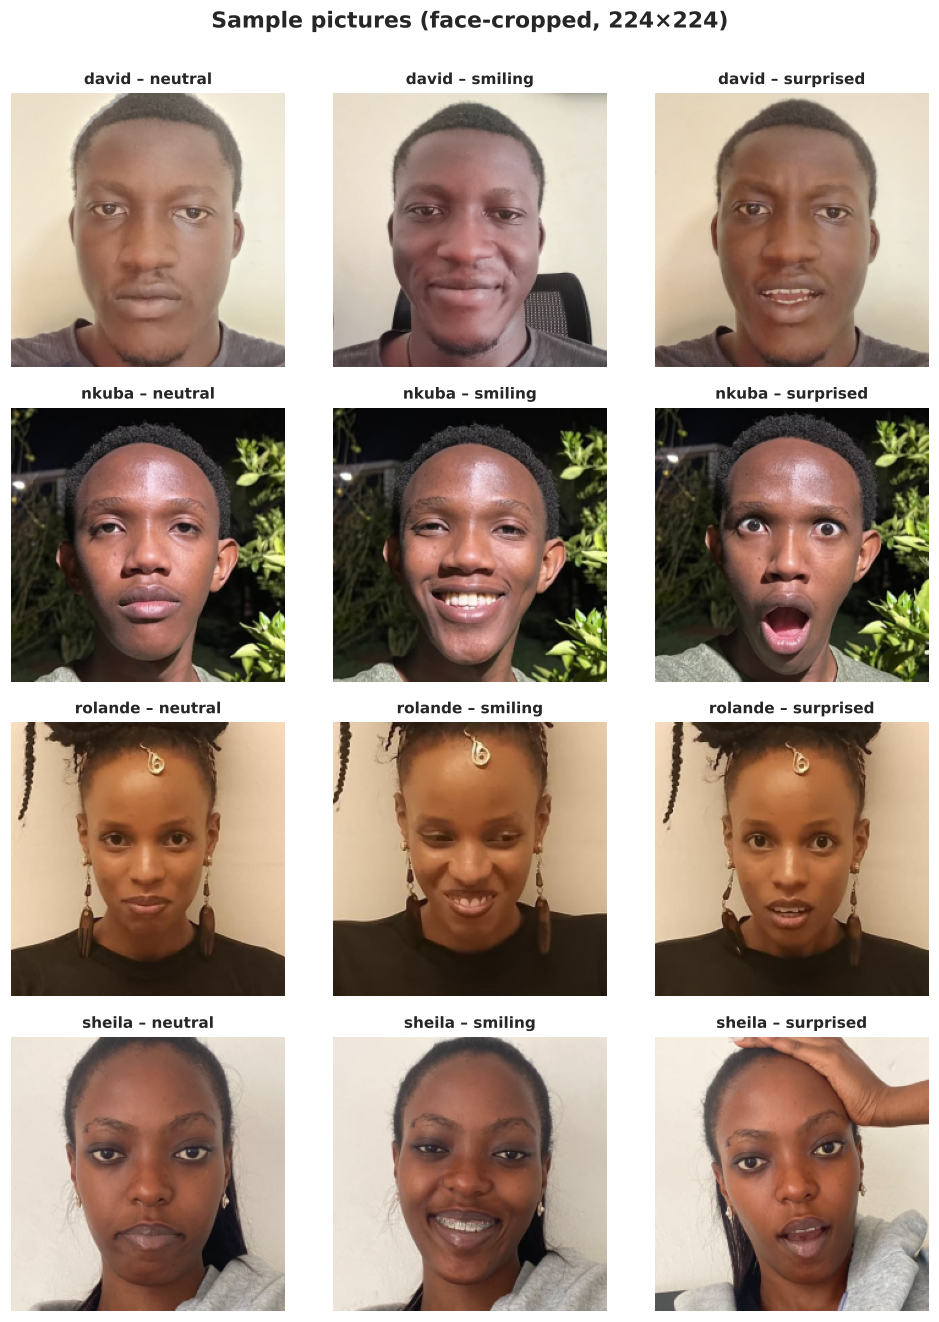

Face detected in 100% of photos


,member,expression,face_detected


In [3]:
members = sorted(inv.member.unique())
fig, axes = plt.subplots(len(members), 3, figsize=(9, 3*len(members)), squeeze=False)
det_log = []
for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        r = inv[(inv.member==m)&(inv.expression==e)].iloc[0]
        img, det = load_face(r.path); det_log.append((m, e, det))
        axes[i][j].imshow(img); axes[i][j].axis('off')
        axes[i][j].set_title(f'{m} – {e}' + ('' if det else '  (no face found)'), fontsize=10)
plt.suptitle('Sample pictures (face-cropped, 224×224)', y=1.0, fontweight='bold'); plt.tight_layout(); plt.savefig(FIG/'img1_samples.png', bbox_inches='tight'); plt.show()
det = pd.DataFrame(det_log, columns=['member','expression','face_detected'])
print(f'Face detected in {det.face_detected.mean():.0%} of photos'); display(det[~det.face_detected])

**Interpretation.** Face detection succeeded on all 12 photos (100 %), so every crop is face-centred. Expression quality: *nkuba* shows three very distinct expressions (relaxed mouth → wide smile with teeth → raised brows, wide eyes, open mouth). *rolande* and *sheila* both have clearly readable neutral, smiling (teeth visible) and surprised (raised brows, open mouth) shots; sheila's *surprised* shot includes a hand on her head. *david*'s neutral and smiling shots are clear, while his *surprised* shot is the mildest of the set (mouth slightly open, brows only slightly raised). All members were photographed against plain indoor walls except nkuba (outdoors at night), and mean brightness differs a lot by person (nkuba ≈ 76, rolande ≈ 117, sheila ≈ 148, david ≈ 157). **Optional improvement:** a stronger surprised expression for david would make the three classes more distinct.

## 4. Augmentation (8 transformations per image)

Augmentations applied to EVERY image: ['rot_plus15', 'rot_minus15', 'flip_h', 'grayscale', 'brighter', 'darker', 'gauss_noise', 'blur']


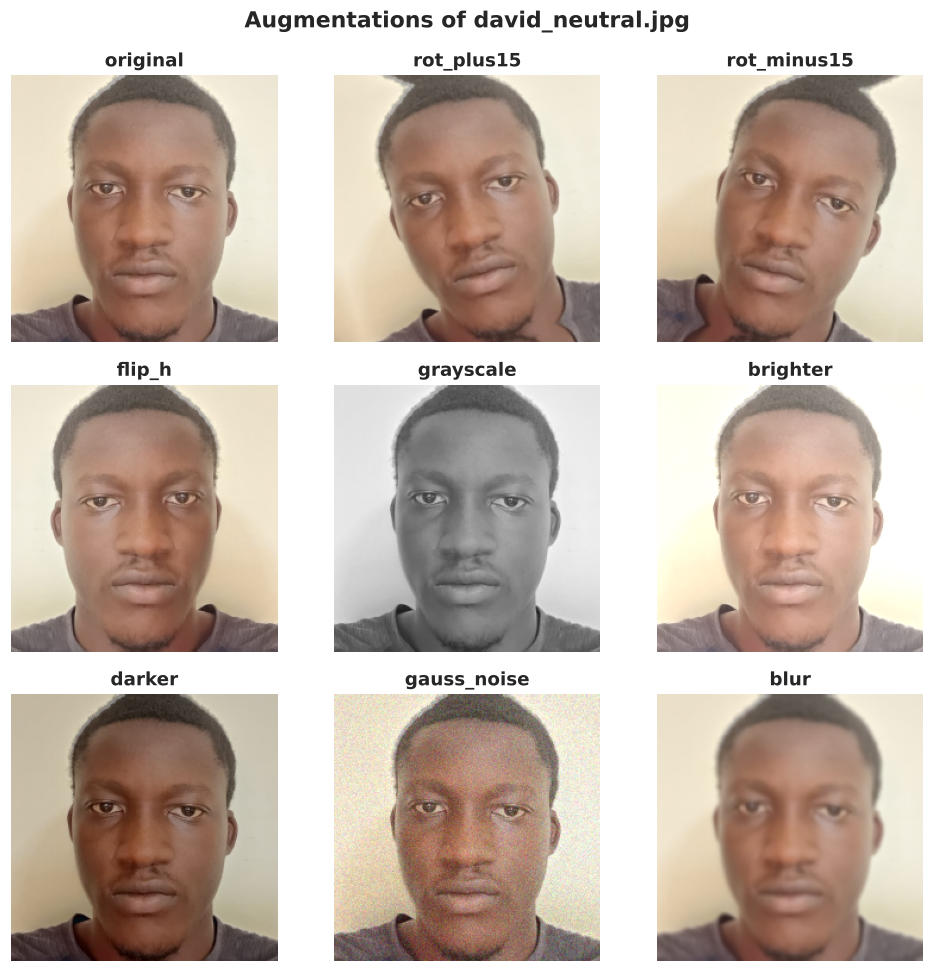

In [4]:
print('Augmentations applied to EVERY image:', list(AUGMENTATIONS))
r = inv.iloc[0]; base, _ = load_face(r.path)
variants = {'original': base} | {k: fn(base) for k, fn in AUGMENTATIONS.items()}
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, (k, im) in zip(axes.ravel(), variants.items()): ax.imshow(im); ax.set_title(k); ax.axis('off')
plt.suptitle(f'Augmentations of {r.file}', fontweight='bold'); plt.tight_layout(); plt.savefig(FIG/'img2_augmentations.png', bbox_inches='tight'); plt.show()

**Why these eight?** *Rotation ±15°* and *horizontal flip* simulate head tilt / mirrored selfie framing; *grayscale* removes colour dependence; *brighter / darker* simulate lighting changes; *Gaussian noise* and *blur* simulate camera noise and out-of-focus shots. Each is label-preserving – the person and expression stay the same – so the face model sees 9× more varied samples per photo.

## 5. Feature extraction → `image_features.csv`

In [5]:
USE_CNN_EMBEDDINGS = False   # True = add 512-d ResNet-18 embeddings (needs: pip install torch torchvision)
feats, report, inv = run_pipeline(IMAGES_DIR, OUT_DIR/'image_features.csv', AUG_DIR, use_embeddings=USE_CNN_EMBEDDINGS)
meta = ['image_id','member','expression','augmentation','is_augmented','face_detected','source_file']
groups = {'colour histogram (16 bins × RGB)':'^hist_', 'HOG (shape / edges)':'^hog_', 'LBP (texture)':'^lbp_',
          'CNN embedding':'^emb_', 'global statistics':'^(mean|std)_|brightness|contrast|sharpness|edge_density'}
print('Saved ->', OUT_DIR/'image_features.csv', '| shape:', feats.shape)
print(f"{(feats.is_augmented==0).sum()} original + {feats.is_augmented.sum()} augmented rows | missing values: {feats.isna().sum().sum()}")
display(pd.Series({g: feats.filter(regex=p).shape[1] for g,p in groups.items()}, name='n_columns').to_frame())
display(feats[meta + list(feats.columns[len(meta):len(meta)+4])].head(6))

Saved -> /home/claude/formative2/data/processed/image_features.csv | shape: (108, 399)
12 original + 96 augmented rows | missing values: 0


,n_columns
colour histogram (16 bins × RGB),48
HOG (shape / edges),324
LBP (texture),10
CNN embedding,0
global statistics,10


,image_id,member,expression,augmentation,is_augmented,face_detected,source_file,hist_r_00,hist_r_01,hist_r_02,hist_r_03
0,david_neutral,david,neutral,original,0,1,david_neutral.jpg,0.0,0.000000,0.000757,0.001315
1,david_neutral,david,neutral,rot_plus15,1,1,david_neutral.jpg,0.0,0.000000,0.000658,0.000996
2,david_neutral,david,neutral,rot_minus15,1,1,david_neutral.jpg,0.0,0.000000,0.000598,0.001016
3,david_neutral,david,neutral,flip_h,1,1,david_neutral.jpg,0.0,0.000000,0.000757,0.001315
4,david_neutral,david,neutral,grayscale,1,1,david_neutral.jpg,0.0,0.000339,0.001734,0.007394
5,david_neutral,david,neutral,brighter,1,1,david_neutral.jpg,0.0,0.000000,0.000000,0.000000


| Feature group | What it captures | Used for |
|---|---|---|
| **RGB histograms** (48) | skin tone / colour distribution | identity cue, lighting sensitivity |
| **HOG** (324) | edge orientations → face shape, mouth/eyebrow geometry | expression + identity |
| **LBP** (10) | local skin / hair texture | identity cue, robust to brightness |
| **Statistics** (≈ 12) | brightness, contrast, sharpness, edge density | quality control, augmentation check |
| *(optional)* **CNN embedding** (512) | learned face-appearance vector | strongest identity signal |

## 6. Feature sanity checks & visualisation

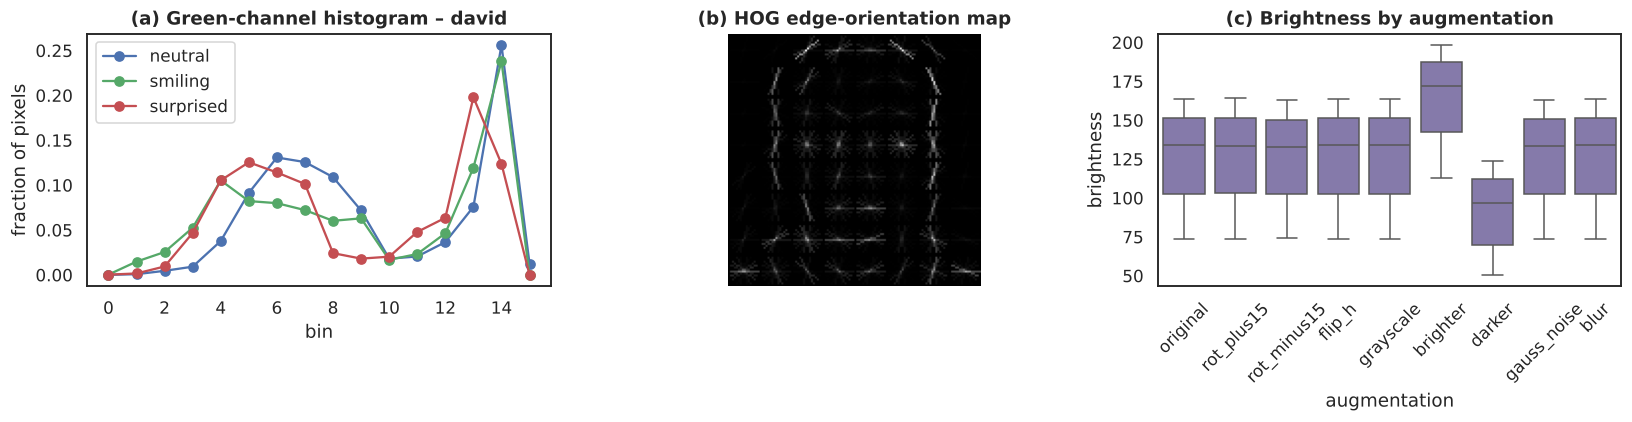

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# (a) colour histograms of the 3 expressions of the first member
m0 = members[0]
for e, col in zip(EXPRESSIONS, ['#4C72B0','#55A868','#C44E52']):
    row = feats[(feats.member==m0)&(feats.expression==e)&(feats.augmentation=='original')].iloc[0]
    ax[0].plot(range(16), [row[f'hist_g_{b:02d}'] for b in range(16)], marker='o', label=e, color=col)
ax[0].set(title=f'(a) Green-channel histogram – {m0}', xlabel='bin', ylabel='fraction of pixels'); ax[0].legend()
# (b) HOG visualisation
g = cv2.cvtColor(base, cv2.COLOR_RGB2GRAY); g = cv2.resize(g, (128,128))
_, hog_img = hog(g, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2), visualize=True)
ax[1].imshow(hog_img, cmap='gray'); ax[1].set_title('(b) HOG edge-orientation map'); ax[1].axis('off')
# (c) augmentation effect on brightness & sharpness
sns.boxplot(data=feats, x='augmentation', y='brightness', ax=ax[2], color='#8172B2'); ax[2].tick_params(axis='x', rotation=45)
ax[2].set_title('(c) Brightness by augmentation'); plt.tight_layout(); plt.savefig(FIG/'img3_feature_checks.png', bbox_inches='tight'); plt.show()

**Interpretation.** (a) The green-channel histograms of different expressions of the same person overlap closely, so colour mostly encodes identity and lighting rather than expression. (b) HOG highlights the eyes, brows, nose and mouth contours – the regions that differ between neutral, smiling and surprised. (c) `brighter` / `darker` shift brightness up and down as intended, while rotation and flip leave it roughly unchanged, confirming each augmentation does what it claims.

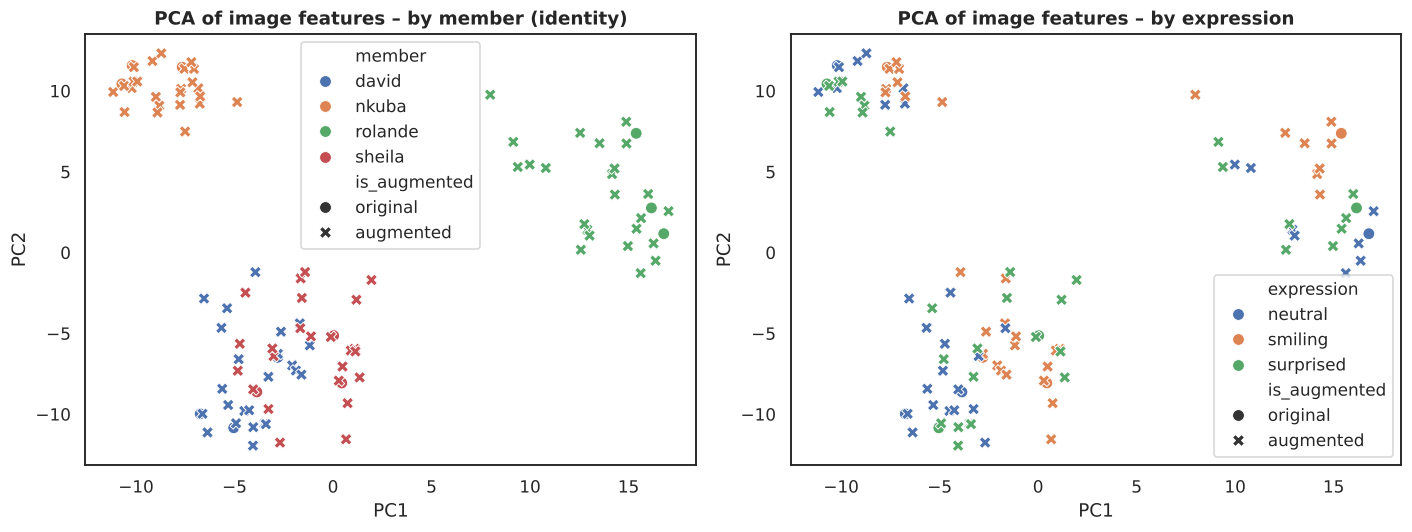

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
X = feats.filter(regex='^(hist_|hog_|lbp_|emb_)'); Z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, hue, ttl in zip(ax, ['member','expression'], ['by member (identity)','by expression']):
    sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=feats[hue], style=feats.is_augmented.map({0:'original',1:'augmented'}), s=60, ax=a)
    a.set(title=f'PCA of image features – {ttl}', xlabel='PC1', ylabel='PC2')
plt.tight_layout(); plt.savefig(FIG/'img4_pca.png', bbox_inches='tight'); plt.show()

**Interpretation.** Nkuba and Rolande each form their own compact cluster (left plot), but **David and Sheila overlap heavily**. Expressions do **not** cluster (right plot). Silhouette scores confirm it: by member 0.22 (colour histograms), 0.25 (HOG), 0.10 (LBP); by expression ≈ 0 for all three (−0.02 to 0.03). Augmented copies (✕) stay close to their original (●), as intended.

⚠️ **Why this matters:** David and Sheila are the two members photographed in the most similar conditions (plain light wall, bright indoor light, grey clothing) – and they are exactly the two the hand-crafted features cannot tell apart, while Nkuba (dark outdoor scene) and Rolande (warm beige wall) separate easily. Earlier versions of this dataset showed the same pattern: when David's neutral photo had a monitor background it moved away from his other two. Together this suggests the colour/HOG features capture **background and lighting more than facial identity**, so a face classifier built on them would be unreliable. For Task 4: use `USE_CNN_EMBEDDINGS=True` (needs `pip install torch torchvision`), crop tighter around the face, use consistent backgrounds, and evaluate with image-level splits. This is a hypothesis from the plots and silhouette scores; it has not been tested with a trained model.

## 7. Notes for Task 4 (Facial Recognition model)
* **Split by `image_id`, never by row.** The 9 rows of one photo (original + 8 augmentations) are near-duplicates; if some land in train and some in test, accuracy is inflated by leakage. Use `GroupKFold(groups=feats.image_id)` or hold out whole photos – e.g. train on neutral+smiling, test on surprised.
* **Label = `member`**; keep `expression` for an expression-robustness check. Drop `image_id`, `source_file`, `is_augmented`, `augmentation`, `face_detected` from X.
* With only 3 photos/member the test set is tiny – report accuracy **and** macro-F1 **and** log-loss, and say so.
* An *unauthorised* face for the demo = a photo of someone **not** in the training set; the model should return low confidence → reject using a probability threshold (e.g. `predict_proba.max() < 0.6`).